# Linear Regression

Fit a straight line (or hyperplane) to data: `ŷ = Xw + b`. The "best" line is the one that minimises the **mean squared error**

$$\text{MSE}(w, b) = \frac1n \sum_i \big(x_i \cdot w + b - y_i\big)^2$$

Two ways to find it, both implemented below:

| Method | Idea | Cost |
|---|---|---|
| `normal_equation` | The MSE is a bowl. Set its gradient to zero and solve: `θ = (XᵀX)⁻¹Xᵀy` (θ = bias and weights stacked, `X` gets a column of ones) | `O(n·d² + d³)`, one shot |
| `gradient_descent` | Walk downhill: `w ← w − lr · (2/n)·Xᵀ(ŷ − y)` | `O(n·d)` per step, many steps |

This notebook is self-contained: the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm. `pinv` (pseudo-inverse) is used instead of `inv` so it still works when features are collinear.

In [2]:
import numpy as np


class LinearRegression:
    """Ordinary least squares regression: y = Xw + b."""

    def __init__(self, method="normal_equation", lr=0.05, n_iters=1000):
        self.method = method
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if self.method == "normal_equation":
            X_b = np.hstack([np.ones((X.shape[0], 1)), X])
            theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
            self.bias, self.weights = theta[0], theta[1:]
        elif self.method == "gradient_descent":
            n_samples, n_features = X.shape
            self.weights = np.zeros(n_features)
            self.bias = 0.0
            for _ in range(self.n_iters):
                y_pred = X @ self.weights + self.bias
                error = y_pred - y
                grad_w = (2 / n_samples) * (X.T @ error)
                grad_b = (2 / n_samples) * np.sum(error)
                self.weights -= self.lr * grad_w
                self.bias -= self.lr * grad_b
        else:
            raise ValueError(f"unknown method: {self.method}")
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.weights + self.bias

## See it work

### 1. The fit

Synthetic data from the line `y = 4x + 7` plus noise. Both methods should land on the same line, and the residuals (what the line gets wrong) should look like structureless noise.

normal equation : w = 4.0403, b = 6.9912
gradient descent: w = 4.0403, b = 6.9909   (true: w = 4, b = 7)


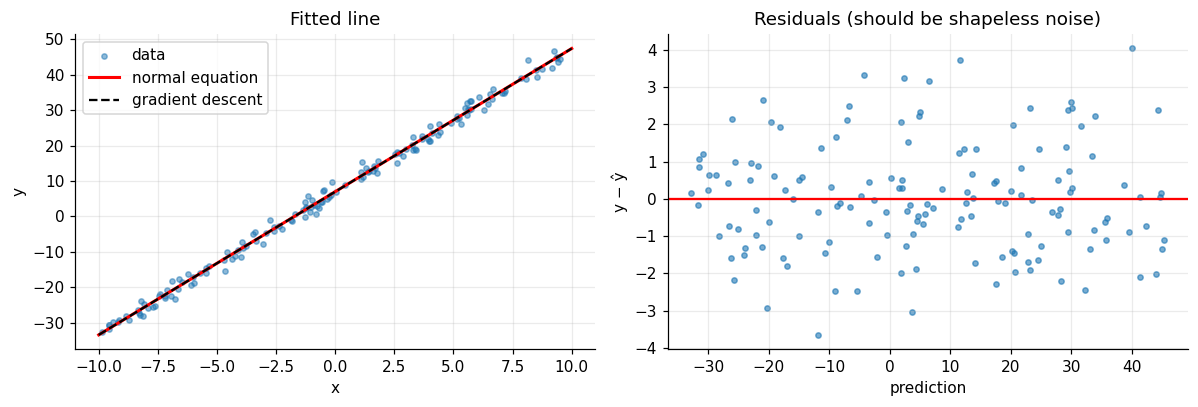

In [3]:
rng = np.random.default_rng(42)
X = rng.uniform(-10, 10, size=(150, 1))
y = 4.0 * X[:, 0] + 7.0 + rng.normal(scale=1.5, size=150)

exact = LinearRegression("normal_equation").fit(X, y)
gd = LinearRegression("gradient_descent", lr=0.01, n_iters=500).fit(X, y)
print(f"normal equation : w = {exact.weights[0]:.4f}, b = {exact.bias:.4f}")
print(f"gradient descent: w = {gd.weights[0]:.4f}, b = {gd.bias:.4f}   (true: w = 4, b = 7)")

xs = np.linspace(-10, 10, 100)[:, None]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.scatter(X, y, s=12, alpha=0.5, label="data")
a.plot(xs, exact.predict(xs), "r", lw=2, label="normal equation")
a.plot(xs, gd.predict(xs), "k--", lw=1.5, label="gradient descent")
a.set(title="Fitted line", xlabel="x", ylabel="y"); a.legend()
b.scatter(exact.predict(X), y - exact.predict(X), s=12, alpha=0.6)
b.axhline(0, color="r"); b.set(title="Residuals (should be shapeless noise)", xlabel="prediction", ylabel="y − ŷ")
plt.tight_layout(); plt.show()

### 2. Gradient descent on the loss surface

The MSE as a function of the two parameters `(w, b)` is a bowl. Each gradient step slides down it. The valley is a long narrow ellipse (the weight is much more sensitive than the bias), which is why gradient descent races down the steep direction (weight) first and then crawls along the flat one (bias).

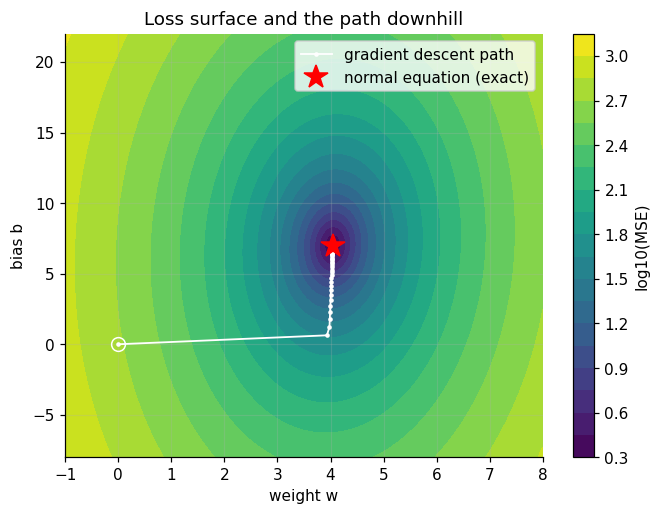

In [4]:
w_grid, b_grid = np.linspace(-1, 8, 150), np.linspace(-8, 22, 150)
W, B = np.meshgrid(w_grid, b_grid)
loss = ((W[..., None] * X[:, 0] + B[..., None] - y) ** 2).mean(-1)

# re-fit with 0, 5, 10, ... iterations to record where gradient descent is after each stretch
path = np.array([[m.weights[0], m.bias] for m in
                 (LinearRegression("gradient_descent", lr=0.01, n_iters=k).fit(X, y) for k in range(0, 401, 5))])

plt.figure(figsize=(7, 5))
plt.contourf(W, B, np.log10(loss), levels=25, cmap="viridis")
plt.colorbar(label="log10(MSE)")
plt.plot(*path.T, "w.-", lw=1.2, ms=4, label="gradient descent path")
plt.plot(exact.weights[0], exact.bias, "r*", ms=16, label="normal equation (exact)")
plt.plot(*path[0], "wo", mfc="none", ms=9)
plt.xlabel("weight w"); plt.ylabel("bias b"); plt.title("Loss surface and the path downhill"); plt.legend()
plt.show()

### 3. The learning rate, and why feature scaling matters

Too small: crawls. Too large: **overshoots and diverges**. The largest safe learning rate depends on the scale of the features (it must stay below `2 / λ_max` where `λ_max` is the largest eigenvalue of `(2/n)·XᵀX`). Here `x` ranges over ±10, so even `lr = 0.035` blows up. After standardising `x` (mean 0, std 1) a learning rate of 0.5 is fine and converges in a handful of steps.

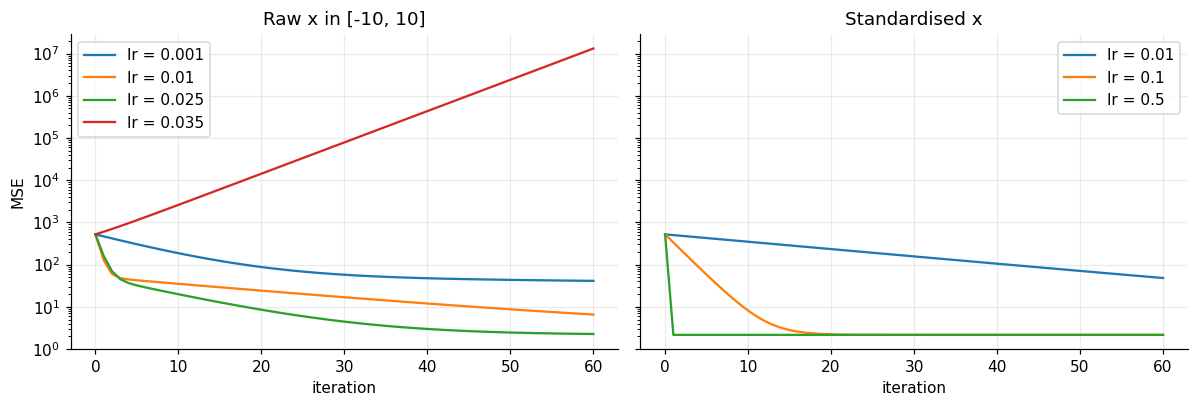

In [5]:
def mse_history(Xin, lr, steps=60):
    out = []
    for k in range(steps + 1):
        m = LinearRegression("gradient_descent", lr=lr, n_iters=k).fit(Xin, y)
        out.append(((m.predict(Xin) - y) ** 2).mean())
    return out

Xs = (X - X.mean(0)) / X.std(0)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for lr in (0.001, 0.01, 0.025, 0.035):
    a.semilogy(mse_history(X, lr), label=f"lr = {lr}")
a.set(title="Raw x in [-10, 10]", xlabel="iteration", ylabel="MSE"); a.legend()
for lr in (0.01, 0.1, 0.5):
    b.semilogy(mse_history(Xs, lr), label=f"lr = {lr}")
b.set(title="Standardised x", xlabel="iteration"); b.legend()
plt.tight_layout(); plt.show()

### 4. Several features

With more than one feature the same code gives one weight per feature. With low noise the normal equation recovers the true weights almost exactly.

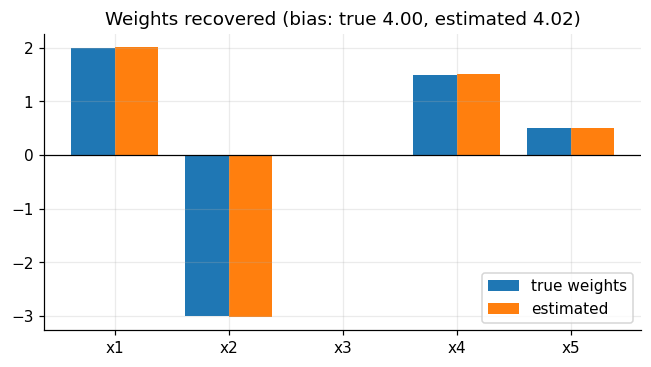

In [6]:
rng = np.random.default_rng(1)
true_w, true_b = np.array([2.0, -3.0, 0.0, 1.5, 0.5]), 4.0
X5 = rng.normal(size=(300, 5))
y5 = X5 @ true_w + true_b + rng.normal(scale=0.3, size=300)
m5 = LinearRegression().fit(X5, y5)

idx = np.arange(5); width = 0.38
plt.figure(figsize=(7, 3.5))
plt.bar(idx - width / 2, true_w, width, label="true weights")
plt.bar(idx + width / 2, m5.weights, width, label="estimated")
plt.xticks(idx, [f"x{i+1}" for i in idx]); plt.axhline(0, color="k", lw=0.8)
plt.title(f"Weights recovered (bias: true 4.00, estimated {m5.bias:.2f})"); plt.legend(); plt.show()

## Check against scikit-learn

The closed-form solution must agree with `sklearn.linear_model.LinearRegression` to numerical precision.

In [7]:
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.metrics import mean_squared_error

theirs = SklearnLinearRegression().fit(X, y)
print("ours   : weight=%.6f bias=%.6f" % (exact.weights[0], exact.bias))
print("sklearn: weight=%.6f bias=%.6f" % (theirs.coef_[0], theirs.intercept_))
mse_ours, mse_theirs = mean_squared_error(y, exact.predict(X)), mean_squared_error(y, theirs.predict(X))
print("MSE    : ours=%.6f sklearn=%.6f" % (mse_ours, mse_theirs))
assert abs(mse_ours - mse_theirs) < 1e-6
print("match")

ours   : weight=4.040272 bias=6.991168
sklearn: weight=4.040272 bias=6.991168
MSE    : ours=2.167258 sklearn=2.167258
match


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [8]:
import numpy as np


def test_recovers_known_line():
    rng = np.random.default_rng(0)
    X = rng.uniform(-10, 10, size=(200, 1))
    true_w, true_b = 3.5, -2.0
    y = true_w * X[:, 0] + true_b

    for method in ("normal_equation", "gradient_descent"):
        model = LinearRegression(method=method, lr=0.01, n_iters=2000).fit(X, y)
        assert abs(model.weights[0] - true_w) < 0.05, method
        assert abs(model.bias - true_b) < 0.05, method

        preds = model.predict(X)
        assert np.allclose(preds, y, atol=0.1), method


def test_multivariate():
    rng = np.random.default_rng(1)
    X = rng.uniform(-5, 5, size=(300, 3))
    true_w = np.array([1.0, -2.0, 0.5])
    true_b = 4.0
    y = X @ true_w + true_b

    model = LinearRegression(method="normal_equation").fit(X, y)
    assert np.allclose(model.weights, true_w, atol=1e-6)
    assert abs(model.bias - true_b) < 1e-6

In [9]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_recovers_known_line
PASS test_multivariate

all 2 tests passed


## Takeaways

- **Use it when** the relationship is roughly linear and you want an interpretable baseline: each weight is "change in `y` per unit of that feature, others fixed". Always try it first.
- **Assumptions:** linear relationship, errors roughly independent with constant variance. Check the residual plot (section 1).
- **Pitfalls:** outliers pull the line hard (squared error). Collinear features make individual weights unstable (use `02_ridge_lasso`). Gradient descent needs scaled features (section 3). A curved relationship needs extra features (`04_polynomial_regression`).
- **Interview line:** *"Model `Xw + b`, loss MSE, solver closed form `solve(XᵀX, Xᵀy)` or gradient `Xᵀ(ŷ − y)/n`."*